# USD/LKR Importer Risk Simulator
A reproducible simulation of a hypothetical Sri Lankan importer’s USD invoice. Historical CBSL-labelled USD telegraphic-transfer **selling** quotes calibrate a calendar-gap GBM; a bounded two-state Markov extension explores volatility regimes. Outputs are conditional model scenarios, not exchange-rate forecasts. Run every cell in order.


In [1]:
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "numpy", "pandas", "scipy", "matplotlib"])
print("Python:", sys.version.split()[0])


Python: 3.13.5


## 1. Problem and question
For a hypothetical USD 100,000 invoice due 90 calendar days after the last 2024 training quote, how large might the LKR payment and extra cost be? How sensitive are upper-tail VaR and Expected Shortfall to the calibration period, volatility and time convention? The 2025–2026 data remain outside the training fit.


In [2]:
from pathlib import Path
import os, sys, subprocess
REPOSITORY_NAME = "usd-lkr-importer-risk-simulator"
REPOSITORY_URL = "https://github.com/D-B-Yesen-Binuwara/usd-lkr-importer-risk-simulator.git"
candidates = [Path.cwd(), Path.cwd()/REPOSITORY_NAME, Path("/content")/REPOSITORY_NAME]
repo_root = next((p.resolve() for p in candidates if (p/"src"/"run_risk.py").is_file() and (p/"data"/"raw"/"CBSL_USD_TT_Selling.csv").is_file()), None)
if repo_root is None:
    target = Path.cwd()/REPOSITORY_NAME
    if target.exists():
        raise RuntimeError("A partial repository exists; obtain a complete project copy before Run all.")
    subprocess.check_call(["git", "clone", "--depth", "1", REPOSITORY_URL, str(target)])
    repo_root = target.resolve()
if str(repo_root) not in sys.path: sys.path.insert(0,str(repo_root))
print("Project:",repo_root.name,"| raw CSV present:",(repo_root/"data/raw/CBSL_USD_TT_Selling.csv").is_file())


Project: usd-lkr-importer-risk-simulator | raw CSV present: True


## 2. Model, assumptions and equations
Let $S_t$ be LKR per USD and $r_i=\ln(S_i/S_{i-1})$. For observed calendar gaps $\Delta t_i=d_i/365$, fit $r_i\sim N(\alpha\Delta t_i,\sigma^2\Delta t_i)$ using only 2019–2024. The exact GBM terminal draw is $S_T=S_0\exp(\alpha T+\sigma\sqrt{T}Z)$, $Z\sim N(0,1)$, $T=90/365$. For invoice size $Q$, cost $C_T=QS_T$ and signed extra cost $L=C_T-QS_0$. VaR95 is the upper 95th percentile of $L$; ES95 averages the upper 5% using the stated quantile-integral convention. The Markov extension labels stable/volatile training increments and samples a row-stochastic state transition matrix before each future quote increment. This applies input modelling/random variates, Monte Carlo integration/LLN, and a DTMC. Fees, spreads and real importer terms are excluded.


## 3. Implementation and source data
The Python modules under `src/` are the single implementation source. The notebook runs the data audit and frozen Stage 6–7 reports directly; no machine-specific absolute path is entered. The bundled CSV is claimed to come from the [CBSL daily buy/sell page](https://www.cbsl.gov.lk/en/rates-and-indicators/exchange-rates/daily-buy-and-sell-exchange-rates). Exact export date, request and reuse terms are unverified. FRED files are reference only.


In [3]:
from src.prepare_data import prepare_data
from src.calibration import baseline_calibration_report
from src.markov import baseline_markov_report
from src.run_risk import baseline_risk_report
from src.experiments import comparison_report
import pandas as pd, numpy as np
from math import sqrt
raw = repo_root/"data/raw/CBSL_USD_TT_Selling.csv"
print("Raw CSV bytes:",raw.stat().st_size)
cal = baseline_calibration_report(repo_root)
markov = baseline_markov_report(repo_root)
returns = pd.read_csv(repo_root/"data/processed/calibration_returns_2019_2024.csv")
print("Training returns:",len(returns),"| last quote:",cal["calibration"]["last_quote_date"])
print("Calendar-gap alpha/sigma:",cal["calibration"]["alpha_per_year"],cal["calibration"]["sigma_per_sqrt_year"])
print("Markov P:",markov["calibration"]["transition_probabilities"])


Raw CSV bytes: 113267
Training returns: 1444 | last quote: 2024-12-31
Calendar-gap alpha/sigma: 0.07919696011210609 0.12081424674804953
Markov P: ((0.8148514851485148, 0.18514851485148515), (0.43187066974595845, 0.5681293302540416))


## 4. Verification
These visible assertions check the training boundary, probability conservation and GBM simulation against an **analytical** mean. The full automated test suite is separate. A passed assertion establishes internal consistency under the assumptions, not CBSL file authenticity or forecasting skill.


In [4]:
from src.gbm import simulate_terminal_rates, theoretical_terminal_moments
cfit=cal["calibration"]
assert len(returns)==1444
assert returns["date"].max()<"2025-01-01"
P=np.asarray(markov["calibration"]["transition_probabilities"])
assert P.shape==(2,2) and np.all((P>=0)&(P<=1)) and np.allclose(P.sum(axis=1),1,atol=1e-12)
S0=cfit["last_rate_lkr_per_usd"]
checks=simulate_terminal_rates(S0,cfit["alpha_per_year"],cfit["sigma_per_sqrt_year"],horizon_days=90,n_paths=100000,seed=2026)
mean,var=theoretical_terminal_moments(S0,cfit["alpha_per_year"],cfit["sigma_per_sqrt_year"],horizon_days=90)
z=abs(np.mean(checks)-mean)/sqrt(var/len(checks))
assert z<4, f"Mean error {z:.2f} MC standard errors"
print(f"PASS: training isolation, Markov row sums, analytical GBM mean ({z:.2f} MC SE)")


PASS: training isolation, Markov row sums, analytical GBM mean (0.10 MC SE)


## 5. Experiments and results
The invoice is hypothetical. Eight independent seeds 42–49 generate 10,000 paths each for GBM and Markov. Mean-cost intervals quantify Monte Carlo sampling error conditional on fitted parameters; between-seed VaR/ES SDs are **not** confidence intervals for tail risk. The comparison fixes invoice, reference rate, due date and seeds while changing calibration window, volatility or clock.


In [5]:
risk=baseline_risk_report(repo_root)
exp=comparison_report(repo_root)
print("USD invoice:",risk["scenario"]["invoice_usd"],"| horizon days:",risk["scenario"]["horizon_calendar_days"],"| seeds:",risk["scenario"]["replicate_seeds"])
rows=[]
for name,part in risk["models"].items():
 m=part["pooled_metrics"]
 rows.append({"model":name,"mean_cost_LKR":m["mean_cost_lkr"],"VaR95_extra_LKR":m["var_lkr"],"ES95_extra_LKR":m["es_lkr"]})
print(pd.DataFrame(rows).round(0).to_string(index=False))
comparisons=[]
for key,part in exp["cases"].items():
 m=part["pooled_metrics"]
 comparisons.append({"case":key,"VaR95_extra_LKR":m["var_lkr"],"ES95_extra_LKR":m["es_lkr"],"VaR_between_seed_SD_LKR":part["between_run_variability"]["var_lkr"]["sample_sd"]})
print(pd.DataFrame(comparisons).round(0).to_string(index=False))
assert exp["cases"]["full"]["pooled_metrics"]==risk["models"]["gbm"]["pooled_metrics"]
print("PASS: Stage 7 full GBM case reproduces Stage 6 pooled metrics")


USD invoice: 100000.0 | horizon days: 90 | seeds: (42, 43, 44, 45, 46, 47, 48, 49)
 model  mean_cost_LKR  VaR95_extra_LKR  ES95_extra_LKR
   gbm     30339206.0        3731194.0       4582741.0
markov     30345423.0        3679169.0       4609172.0
        case  VaR95_extra_LKR  ES95_extra_LKR  VaR_between_seed_SD_LKR
        full        3731194.0       4582741.0                  25632.0
    pre_2022        1674284.0       2050227.0                  11452.0
   post_2022        5254076.0       6448509.0                  35679.0
exclude_2022        1719723.0       2223006.0                  15276.0
    vol_0_75        2915451.0       3534944.0                  18754.0
    vol_1_50        5424395.0       6782090.0                  40398.0
 session_252        3425303.0       4175513.0                  22638.0
PASS: Stage 7 full GBM case reproduces Stage 6 pooled metrics


Observed RMSE log-log slope: -0.495 (theory: -0.5)


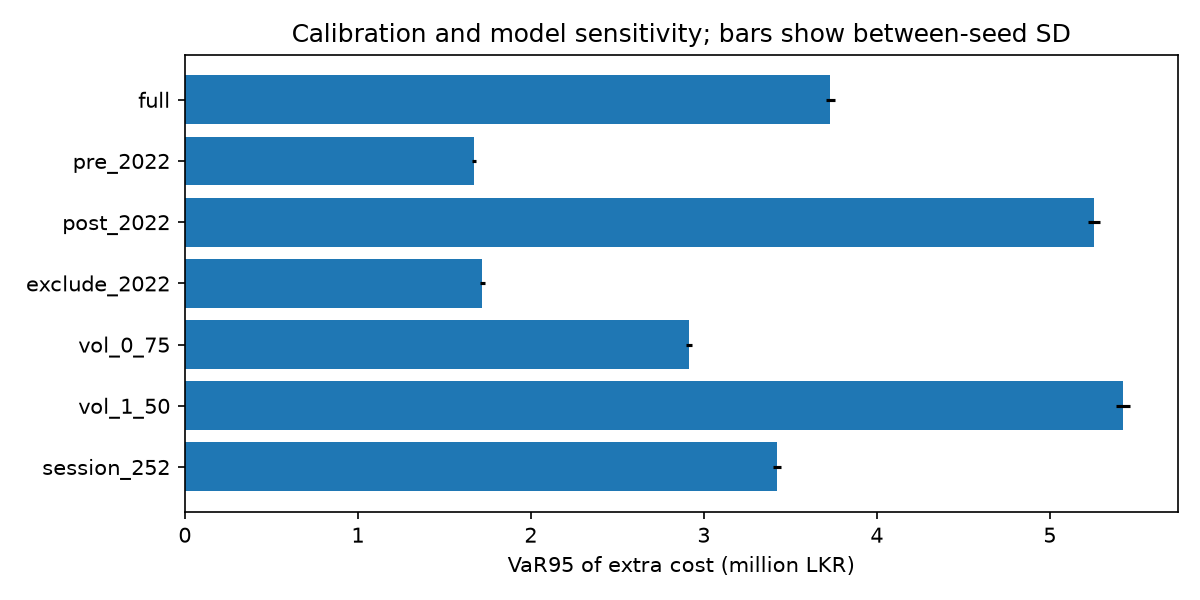

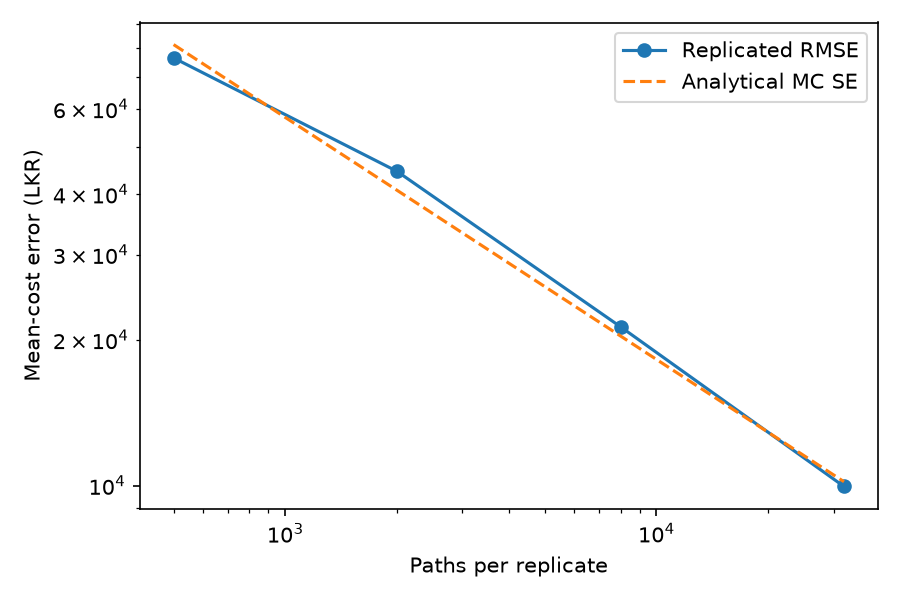

In [6]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,4))
tab=pd.DataFrame(comparisons)
ax.barh(tab["case"],tab["VaR95_extra_LKR"]/1e6,xerr=tab["VaR_between_seed_SD_LKR"]/1e6)
ax.set_xlabel("VaR95 of extra cost (million LKR)")
ax.set_title("Calibration and model sensitivity; bars show between-seed SD")
ax.invert_yaxis();plt.tight_layout();plt.show()
conv=exp["convergence"]
fig,ax=plt.subplots(figsize=(6,4))
ax.loglog([p["n_paths"] for p in conv["points"]],[p["rmse_mean_cost_lkr"] for p in conv["points"]],"o-",label="Replicated RMSE")
ax.loglog([p["n_paths"] for p in conv["points"]],[p["theoretical_mc_se_lkr"] for p in conv["points"]],"--",label="Analytical MC SE")
ax.set_xlabel("Paths per replicate");ax.set_ylabel("Mean-cost error (LKR)");ax.legend();plt.tight_layout();plt.show()
print("Observed RMSE log-log slope:",round(conv["log_log_rmse_slope"],3),"(theory: -0.5)")


### Browser parity fixture
The web demo embeds these frozen parameters and uses the same explicit shocks and 20/30/40-day intervals. Browser and Python terminal FX and payment must agree within relative tolerance $10^{-7}$. Numeric seeds alone are not compared because the random-number generators differ.


In [7]:
from src.gbm import exact_gbm_step
parity_rate = S0
for days, shock in zip((20, 30, 40), (0.25, -1.0, 0.5), strict=True):
    parity_rate = exact_gbm_step(parity_rate, cfit["alpha_per_year"], cfit["sigma_per_sqrt_year"], days/365, shock)
parity_payment = 100_000 * parity_rate
assert abs(parity_rate - 300.58956647716474) <= 1e-7 * max(1, abs(parity_rate))
assert abs(parity_payment - 30058956.647716474) <= 1e-7 * max(1, abs(parity_payment))
print(f"Browser fixture: rate {parity_rate:.11f} LKR/USD; payment LKR {parity_payment:.8f}; PASS")


Browser fixture: rate 300.58956647716 LKR/USD; payment LKR 30058956.64771647; PASS


## 6. Discussion and limitations
In the current frozen 2024-boundary exercise, including the 2022 movements raises estimated risk relative to the pre-2022 and 2022-excluded fits. This demonstrates calibration sensitivity, not predictive superiority. The calendar-gap GBM assumes Brownian variance accrues through non-quotation days. The alternate 252-session case assumes 64 future weekday quotes and ignores holidays/settlement. A constant GBM and simple two-state Markov chain cannot establish future regime behaviour. The 2025–2026 snapshot is held out and no predictive backtest is claimed. Monte Carlo intervals omit parameter uncertainty; source-file lineage and redistribution rights remain unresolved.


## 7. References
1. Central Bank of Sri Lanka, [Daily Buy and Sell Exchange Rates](https://www.cbsl.gov.lk/en/rates-and-indicators/exchange-rates/daily-buy-and-sell-exchange-rates). Official page reported by the downloader; exact local CSV export details unverified.
2. Board of Governors of the Federal Reserve System, [FRED DEXSLUS](https://fred.stlouisfed.org/series/DEXSLUS). Supplementary reference only; different quote definition.
3. Project [theory](../THEORY.md), [data decisions](../data/README.md) and [full references](../REFERENCES.md) accompany the repository copy.
